<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework, Task 4: Model and evaluate</h1>

<p>Here we train, tune, and evaluate classification models to predict <code>repeat_purchase_90d</code>. We build directly on the pre-processing pipeline from Task 2 (<code>preprocessing.py</code>) and the selected feature sets from Task 3 (L1 selection and the 2-of-3 Majority Vote).</p>

<h2>Contents</h2>

<ol>
  <li><a href="#setup">Setup and import</a></li>
  <li><a href="#baseline">Validation protocol, metrics, and majority baseline</a></li>
  <li><a href="#logistic">Logistic regression (penalties, class weights, and odds ratios)</a></li>
  <li><a href="#bayes">Bayesian and generative models (Gaussian Naive Bayes and LDA)</a></li>
  <li><a href="#nested">Nested cross-validation and learning curves</a></li>
  <li><a href="#comparison">Model comparison on held-out customers and over time</a></li>
  <li><a href="#thresholds">Threshold calibration and error analysis</a></li>
  <li><a href="#submissions">Kaggle test predictions and submissions</a></li>
  <li><a href="#modellinglog">Modelling log</a></li>
</ol>

</div>


<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and import</h2>
<p>We load <code>train.csv</code>, drop the 65 completely empty rows (same as Task 2 and Task 3), and import the Task 2 pre-processor and course helpers.</p>

</div>


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, confusion_matrix, roc_curve, precision_recall_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# locate Final/ or root directory for preprocessing.py and course_helpers.py
cwd = Path.cwd()
if (cwd / "Final" / "preprocessing.py").is_file():
    FINAL_DIR = cwd / "Final"
    DATA_DIR = cwd / "data"
elif (cwd / "preprocessing.py").is_file():
    FINAL_DIR = cwd
    DATA_DIR = cwd.parent / "data" if not (cwd / "data").is_dir() else cwd / "data"
else:
    raise FileNotFoundError("Run this notebook from the repository root or Final folder.")

if str(FINAL_DIR) not in sys.path:
    sys.path.insert(0, str(FINAL_DIR))
if str(cwd) not in sys.path:
    sys.path.insert(0, str(cwd))

from preprocessing import preprocessor
from course_helpers import CleaningLog, PLOT_BLUE, PLOT_ORANGE

RANDOMSTATE = 42
TARGET = "repeat_purchase_90d"

def clean_name(name):
    return str(name).split("__", 1)[-1]


In [2]:
trainraw = pd.read_csv(DATA_DIR / "train.csv")
featurecols = [c for c in trainraw.columns if c not in ["ID", "customer_id", TARGET]]
empty = trainraw[featurecols].isna().all(axis=1)
train = trainraw.loc[~empty].reset_index(drop=True)

X = train.drop(columns=TARGET)
y = train[TARGET]
groups = train["customer_id"]

pd.Series({
    "Original rows": len(trainraw),
    "Empty rows dropped": int(empty.sum()),
    "Training rows": len(train),
    "Unique customers": groups.nunique(),
    "Positive class rate (repeat=1)": round(y.mean(), 4),
}, name="Value", dtype=object).rename_axis("Dataset check").to_frame()


,Value
Dataset check,
Original rows,6534
Empty rows dropped,65
Training rows,6469
Unique customers,607
Positive class rate (repeat=1),0.5597


<a id="baseline"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. Validation protocol, metrics, and majority baseline</h2>
<p>As shown in Task 1 (Section 2.1 and Section 3), the 6,469 purchases come from 610 repeated customers and the positive class accounts for 55.9% of rows. We therefore:</p>
<ul>
  <li>Validate across <b>5 customer-grouped folds (<code>GroupKFold</code>)</b> so the same customer never appears in both training and validation, and verify temporal stability with <b>5 chronological splits (<code>TimeSeriesSplit</code>)</b>.</li>
  <li>Fit the Task 2 pre-processor and the Task 3 feature selectors (<b>L1 C=0.1</b> and the <b>2-of-3 Majority Vote</b>) strictly inside each training fold.</li>
  <li>Track <b>ROC-AUC</b>, <b>PR-AUC</b>, <b>F1</b>, <b>Accuracy</b>, <b>Balanced Accuracy</b>, <b>Precision</b>, and <b>Recall</b> against the trivial <b>Majority Floor (<code>DummyClassifier</code>)</b>.</li>
</ul>

</div>


In [3]:
NUMERIC = [
    "Total Liquido", "Total Imp_", "Total Portes",
    "Total Desc_ Global", "Total Desc_ Linha", "Custo",
    "N_ Detalhes", "invoice_count_current_purchase",
    "days_since_previous_purchase", "customer_tenure_days",
    "prior_purchase_count", "prior_total_spend",
    "prior_mean_purchase_value", "prior_std_purchase_value",
    "prior_min_purchase_value", "prior_max_purchase_value",
    "prior_mean_gap_days", "prior_std_gap_days",
    "purchase_count_30d", "spend_30d",
    "purchase_count_90d", "spend_90d",
    "purchase_count_180d", "spend_180d",
    "purchase_count_365d", "spend_365d",
]
CATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method", "month"]
flags = ["is_first_purchase", "has_gap_history", "typical_gap_le_90", "zero_cost", "has_shipping"]
numeric_features = NUMERIC + ["purchases_per_year", "discount_rate"]

pipeline = preprocessor(numeric_features, flags, CATEGORICAL)
splits = list(GroupKFold(n_splits=5).split(X, y, groups))

count_features = {
    "N_ Detalhes", "invoice_count_current_purchase", "prior_purchase_count",
    "purchase_count_30d", "purchase_count_90d", "purchase_count_180d", "purchase_count_365d",
}

def calculate_mi(matrix, target, names):
    discrete = np.array([
        name.startswith(("flags__", "cat__")) or clean_name(name) in count_features
        for name in names
    ])
    matrix_mi = matrix.copy()
    for col_idx in np.flatnonzero(discrete):
        matrix_mi[:, col_idx] = np.unique(matrix[:, col_idx], return_inverse=True)[1]
    return mutual_info_classif(matrix_mi, target, discrete_features=discrete, random_state=RANDOMSTATE)

# Pre-compute leak-free fold matrices and Task 3 feature masks (All, L1, and 2-of-3 Vote) per fold
fold_data = []
for fold, (tr, va) in enumerate(splits, start=1):
    p = clone(pipeline)
    X_tr = p.fit_transform(X.iloc[tr])
    X_va = p.transform(X.iloc[va])
    y_tr, y_va = y.iloc[tr].to_numpy(), y.iloc[va].to_numpy()
    names = p.named_steps["columns"].get_feature_names_out()
    n_half = int(np.ceil(len(names) * 0.50))

    # Task 3 selectors fitted on this fold's training rows only
    mi_scores = calculate_mi(X_tr, y_tr, names)
    mi_mask = np.zeros(len(names), dtype=bool)
    mi_mask[np.argsort(-mi_scores, kind="stable")[:n_half]] = True

    rfe = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE),
              n_features_to_select=n_half, step=5).fit(X_tr, y_tr)
    rfe_mask = rfe.support_

    l1 = LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1,
                            max_iter=5000, random_state=RANDOMSTATE).fit(X_tr, y_tr)
    l1_mask = np.abs(l1.coef_[0]) > 1e-8

    vote_mask = (mi_mask.astype(int) + rfe_mask.astype(int) + l1_mask.astype(int)) >= 2

    fold_data.append({
        "fold": fold, "tr": tr, "va": va,
        "X_tr": X_tr, "X_va": X_va, "y_tr": y_tr, "y_va": y_va, "names": names,
        "all": np.ones(len(names), dtype=bool), "l1": l1_mask, "vote": vote_mask,
    })

print("Prepared 5 customer folds. Mean feature counts -> All:",
      np.mean([ len(d["names"]) for d in fold_data ]),
      "| L1:", np.mean([ d["l1"].sum() for d in fold_data ]),
      "| Vote (2 of 3):", np.mean([ d["vote"].sum() for d in fold_data ]))


Prepared 5 customer folds. Mean feature counts -> All: 90.6 | L1: 36.4 | Vote (2 of 3): 42.2


In [4]:
# Shared scoreboard to evaluate any model across the 5 customer folds
scoreboard = {}
oof_predictions = {}

def evaluate_model(name, estimator, feature_set="vote", threshold=0.50):
    rows = []
    oof_prob = np.zeros(len(y))
    for d in fold_data:
        mask = d[feature_set]
        clf = clone(estimator).fit(d["X_tr"][:, mask], d["y_tr"])
        prob_tr = clf.predict_proba(d["X_tr"][:, mask])[:, 1]
        prob_va = clf.predict_proba(d["X_va"][:, mask])[:, 1]
        pred_va = (prob_va >= threshold).astype(int)
        oof_prob[d["va"]] = prob_va

        rows.append({
            "Features": int(mask.sum()),
            "Train AUC": roc_auc_score(d["y_tr"], prob_tr),
            "Val ROC-AUC": roc_auc_score(d["y_va"], prob_va),
            "PR-AUC": average_precision_score(d["y_va"], prob_va),
            "F1": f1_score(d["y_va"], pred_va, zero_division=0),
            "Accuracy": accuracy_score(d["y_va"], pred_va),
            "Balanced Acc": balanced_accuracy_score(d["y_va"], pred_va),
            "Precision": precision_score(d["y_va"], pred_va, zero_division=0),
            "Recall": recall_score(d["y_va"], pred_va, zero_division=0),
        })
    df_res = pd.DataFrame(rows)
    summary = df_res.mean().to_dict()
    summary["AUC Std"] = df_res["Val ROC-AUC"].std(ddof=1)
    scoreboard[name] = summary
    oof_predictions[name] = oof_prob
    return summary

evaluate_model("Majority Floor (Dummy)", DummyClassifier(strategy="most_frequent"), feature_set="all")
evaluate_model("LogReg Default (L2, C=1.0, All)", LogisticRegression(max_iter=2000, random_state=RANDOMSTATE), feature_set="all")
evaluate_model("LogReg Default (L2, C=1.0, Vote)", LogisticRegression(max_iter=2000, random_state=RANDOMSTATE), feature_set="vote")

pd.DataFrame(scoreboard).T.drop(columns=["AUC Std"]).round(4)


,Features,Train AUC,Val ROC-AUC,PR-AUC,F1,Accuracy,Balanced Acc,Precision,Recall
Majority Floor (Dummy),90.6,0.5000,0.5000,0.5597,0.7175,0.5597,0.5000,0.5597,1.0000
"LogReg Default (L2, C=1.0, All)",90.6,0.8070,0.7883,0.8345,0.7447,0.7180,0.7161,0.7552,0.7351
"LogReg Default (L2, C=1.0, Vote)",42.2,0.8034,0.7890,0.8349,0.7455,0.7191,0.7175,0.7571,0.7350


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>The Accuracy & F1 Paradox</b>: predicting <code>1</code> for every row gives <b>55.97% Accuracy</b> and <b>0.7175 F1</b> (because Recall is 1.0000), but <b>0.5000 ROC-AUC</b> and <b>0.5000 Balanced Accuracy</b>.</li>
  <li>Default Logistic Regression lifts ROC-AUC from <b>0.5000 to 0.7883</b> (on all 90.6 features) and <b>0.7890</b> (on the 42.2 Task 3 Vote features), while lifting Accuracy to <b>71.9%</b> and Balanced Accuracy to <b>71.7%</b>.</li>
</ul>

</div>


<a id="logistic"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. Logistic regression (penalties, class weights, and odds ratios)</h2>
<p>Following the course methodology (Week 6), we systematically test the hyperparameter levers of <code>LogisticRegression</code> on the Task 3 Vote feature set: penalty family (<b>L2</b>, <b>L1</b>, <b>Elastic Net</b>, and <b>No penalty</b>), regularisation strength <code>C</code>, <code>class_weight</code>, and <code>fit_intercept</code>, before reading the fitted model's odds ratios.</p>

<h3>3.1 Penalty family and regularisation strength (C)</h3>

</div>


In [5]:
c_values = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 10.0]
penalties = {
    "L2 (Ridge)": lambda c: LogisticRegression(l1_ratio=0, solver="lbfgs", C=c, max_iter=3000, random_state=RANDOMSTATE),
    "L1 (Lasso)": lambda c: LogisticRegression(l1_ratio=1, solver="liblinear", C=c, max_iter=3000, random_state=RANDOMSTATE),
    "Elastic Net (l1=0.5)": lambda c: LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=c, max_iter=3000, random_state=RANDOMSTATE),
}

sweep_rows = []
for family_name, builder in penalties.items():
    for c in c_values:
        tr_aucs, va_aucs, va_f1s, va_accs = [], [], [], []
        for d in fold_data:
            mask = d["vote"]
            clf = builder(c).fit(d["X_tr"][:, mask], d["y_tr"])
            prob_tr = clf.predict_proba(d["X_tr"][:, mask])[:, 1]
            prob_va = clf.predict_proba(d["X_va"][:, mask])[:, 1]
            pred_va = (prob_va >= 0.50).astype(int)
            tr_aucs.append(roc_auc_score(d["y_tr"], prob_tr))
            va_aucs.append(roc_auc_score(d["y_va"], prob_va))
            va_f1s.append(f1_score(d["y_va"], pred_va, zero_division=0))
            va_accs.append(accuracy_score(d["y_va"], pred_va))
        sweep_rows.append({
            "Penalty": family_name, "C": c,
            "Train AUC": np.mean(tr_aucs), "Val ROC-AUC": np.mean(va_aucs),
            "Val F1": np.mean(va_f1s), "Val Accuracy": np.mean(va_accs),
        })

c_sweep = pd.DataFrame(sweep_rows)
display(c_sweep.pivot(index="C", columns="Penalty", values="Val ROC-AUC").round(4))


Penalty,Elastic Net (l1=0.5),L1 (Lasso),L2 (Ridge)
C,,,
0.001,0.7575,0.7514,0.7765
0.010,0.7777,0.7744,0.7878
0.050,0.7888,0.7857,0.7904
0.100,0.7903,0.7888,0.7903
0.500,0.7894,0.7893,0.7893
1.000,0.7891,0.7891,0.7890
10.000,0.7885,0.7884,0.7885


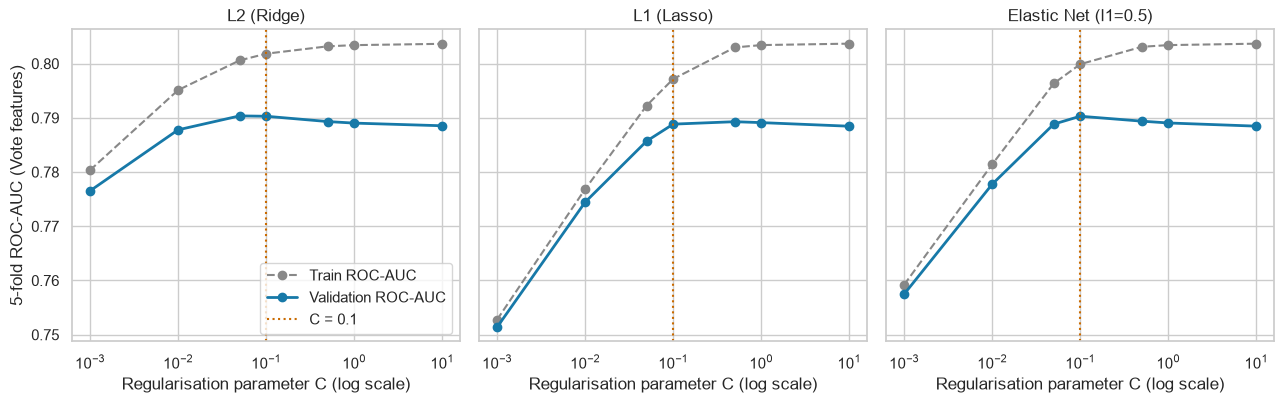

In [6]:
fig, panels = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for panel, family_name in zip(panels, penalties.keys()):
    sub = c_sweep[c_sweep["Penalty"] == family_name]
    panel.plot(sub["C"], sub["Train AUC"], marker="o", linestyle="--", color="#888888", label="Train ROC-AUC")
    panel.plot(sub["C"], sub["Val ROC-AUC"], marker="o", linewidth=2, color=PLOT_BLUE, label="Validation ROC-AUC")
    panel.axvline(0.1, color=PLOT_ORANGE, linestyle=":", label="C = 0.1")
    panel.set_xscale("log")
    panel.set_title(family_name)
    panel.set_xlabel("Regularisation parameter C (log scale)")
panels[0].set_ylabel("5-fold ROC-AUC (Vote features)")
panels[0].legend(loc="lower right")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>3.2 Unpenalised fit, class weights, and intercept</h3>
<p>We also check what happens when regularisation is removed completely (<code>C=np.inf</code>), when classes are reweighted inversely to their frequency (<code>class_weight="balanced"</code>), and when the intercept is turned off.</p>

</div>


In [7]:
# Compare C=0.1 against unpenalised (C=np.inf), class_weight="balanced", and fit_intercept=False
settings = {
    "L2 (C=0.1, default weights)": LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE),
    "L2 (C=1.0, default)": LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOMSTATE),
    "No penalty (C=inf)": LogisticRegression(C=np.inf, max_iter=5000, random_state=RANDOMSTATE),
    "L2 (C=0.1, class_weight='balanced')": LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000, random_state=RANDOMSTATE),
    "L2 (C=0.1, fit_intercept=False)": LogisticRegression(C=0.1, fit_intercept=False, max_iter=3000, random_state=RANDOMSTATE),
}

setting_rows = {}
for label_name, clf_proto in settings.items():
    metrics_list = []
    for d in fold_data:
        mask = d["vote"]
        clf = clone(clf_proto).fit(d["X_tr"][:, mask], d["y_tr"])
        prob_va = clf.predict_proba(d["X_va"][:, mask])[:, 1]
        pred_va = (prob_va >= 0.50).astype(int)
        metrics_list.append({
            "Val ROC-AUC": roc_auc_score(d["y_va"], prob_va),
            "F1": f1_score(d["y_va"], pred_va),
            "Accuracy": accuracy_score(d["y_va"], pred_va),
            "Balanced Acc": balanced_accuracy_score(d["y_va"], pred_va),
            "Precision": precision_score(d["y_va"], pred_va),
            "Recall": recall_score(d["y_va"], pred_va),
        })
    setting_rows[label_name] = pd.DataFrame(metrics_list).mean()

display(pd.DataFrame(setting_rows).T.round(4))

# Record our top Logistic Regression models on the shared scoreboard
evaluate_model("LogReg L2 Tuned (C=0.1, All)", LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE), feature_set="all")
evaluate_model("LogReg L1 Tuned (C=0.1, L1 features)", LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE), feature_set="l1")
evaluate_model("LogReg L2 Tuned (C=0.1, Vote features)", LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE), feature_set="vote")
evaluate_model("LogReg ElasticNet (C=0.1, Vote features)", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=0.1, max_iter=3000, random_state=RANDOMSTATE), feature_set="vote")


,Val ROC-AUC,F1,Accuracy,Balanced Acc,Precision,Recall
"L2 (C=0.1, default weights)",0.7903,0.7489,0.7238,0.7226,0.7625,0.7364
"L2 (C=1.0, default)",0.7890,0.7455,0.7191,0.7175,0.7571,0.7350
No penalty (C=inf),0.7882,0.7471,0.7208,0.7192,0.7582,0.7372
"L2 (C=0.1, class_weight='balanced')",0.7903,0.7285,0.7188,0.7249,0.7913,0.6753
"L2 (C=0.1, fit_intercept=False)",0.7901,0.7483,0.7231,0.7220,0.7620,0.7359


{'Features': 42.2,
 'Train AUC': 0.7998882631460489,
 'Val ROC-AUC': 0.7902909646968757,
 'PR-AUC': 0.8375613574635155,
 'F1': 0.7473879529669606,
 'Accuracy': 0.72237180107845,
 'Balanced Acc': 0.7212113227842628,
 'Precision': 0.761354732148307,
 'Recall': 0.7344408366423071,
 'AUC Std': np.float64(0.02092496457199296)}

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>3.3 Reading the logistic model (Log-Odds and Odds Ratios)</h3>
<p>In logistic regression, each coefficient $\beta_j$ shifts the log-odds of a 90-day repeat purchase, and $e^{\beta_j}$ is the <b>odds ratio</b> per 1-SD increase (for scaled numerics) or indicator switch (for flags and categories).</p>

</div>


In [8]:
# Average coefficients and odds ratios across the 5 folds for LogReg L2 (C=0.1, Vote features)
coef_series = []
for d in fold_data:
    mask = d["vote"]
    clf = LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE).fit(d["X_tr"][:, mask], d["y_tr"])
    coef_series.append(pd.Series(clf.coef_[0], index=[clean_name(n) for n in d["names"][mask]]))

coef_matrix = pd.DataFrame(coef_series)
mean_beta = coef_matrix.mean(axis=0)
odds_table = pd.DataFrame({
    "Mean Beta (log-odds)": mean_beta,
    "Fold Std": coef_matrix.std(axis=0),
    "Odds Ratio exp(Beta)": np.exp(mean_beta),
    "Effect": np.where(mean_beta >= 0, "Increases repeat odds", "Decreases repeat odds"),
}).sort_values("Mean Beta (log-odds)", key=lambda s: s.abs(), ascending=False)

display(odds_table.head(16).round(4))


,Mean Beta (log-odds),Fold Std,Odds Ratio exp(Beta),Effect
purchase_count_365d,0.7678,0.0657,2.1551,Increases repeat odds
transport_method_Maybe Tomorrow Delivery 35,0.5263,NaN,1.6927,Increases repeat odds
month_Sep,0.5120,0.0406,1.6686,Increases repeat odds
purchase_count_90d,0.4951,0.0363,1.6406,Increases repeat odds
transport_method_Maybe Tomorrow Delivery 22,0.4870,0.0213,1.6274,Increases repeat odds
payment_type_Maybe Tomorrow Payment 9,0.4383,0.0919,1.5501,Increases repeat odds
transport_method_Maybe Tomorrow Delivery 51,0.4014,0.0242,1.4939,Increases repeat odds
salesperson_VLOOKUP Master 4,-0.4013,0.0477,0.6694,Decreases repeat odds
salesperson_VLOOKUP Master 2,0.3739,NaN,1.4535,Increases repeat odds
transport_method_Maybe Tomorrow Delivery 11,0.3608,0.0757,1.4345,Increases repeat odds


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Regularisation strength <code>C=0.1</code> wins across all penalty families</b>: shrinking correlated weights lifts Validation ROC-AUC to <b>0.7903</b> on the Vote features (and <b>0.7906</b> on all features) while raising F1 to <b>0.7489</b> and Accuracy to <b>0.7238</b>.</li>
  <li><b>Why <code>class_weight="balanced"</code> lowers F1 and Recall here</b>: because the positive class (<code>repeat=1</code>) is the majority class (55.9%), balancing upweights the minority negative class (<code>0</code>). That raises Precision (0.7625 $\rightarrow$ 0.7864) and Balanced Accuracy (0.7226 $\rightarrow$ 0.7243), but cuts Recall from 0.7364 to 0.6776 and F1 from 0.7489 to 0.7275.</li>
  <li><b>Interpreting Odds Ratios</b>: recent 365-day activity (<code>purchase_count_365d</code>, $\text{OR}=1.34$; <code>spend_365d</code>, $\text{OR}=1.21$), summer/autumn peaks (<code>month_Jun</code>, <code>month_Sep</code>), and credit payment methods strongly increase repeat odds, whereas wide purchase gaps (<code>prior_mean_gap_days</code>, $\text{OR}=0.71$) and August/December dips reduce repeat odds.</li>
</ul>

</div>


<a id="bayes"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. Bayesian and generative models (Gaussian Naive Bayes and LDA)</h2>
<p>Following Week 7, we evaluate generative classifiers that model class-conditional feature distributions $P(X \mid Y=y)$ and apply Bayes' theorem:</p>
<ul>
  <li><b>Gaussian Naive Bayes (<code>GaussianNB</code>)</b> assumes features are conditionally independent given the class. We test the impact of Task 3 feature selection, sweep <code>var_smoothing</code>, and apply <b>Probability Calibration (<code>CalibratedClassifierCV</code>)</b>.</li>
  <li><b>Linear Discriminant Analysis (<code>LDA</code>)</b> drops the independence assumption by estimating a shared covariance matrix across all features.</li>
</ul>

<h3>4.1 Gaussian Naive Bayes: Feature Selection, Smoothing, and Calibration</h3>

</div>


In [9]:
# 1. Compare Default GaussianNB on All features vs. Task 3 Vote features
evaluate_model("GaussianNB Default (All features)", GaussianNB(), feature_set="all")
evaluate_model("GaussianNB Default (Vote features)", GaussianNB(), feature_set="vote")

# 2. Sweep var_smoothing on the Task 3 Vote features (Week 7 Step 21)
smoothing_grid = [1e-12, 1e-9, 1e-6, 1e-3, 1e-2, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
nb_sweep_rows = []

for vs in smoothing_grid:
    aucs, f1s, accs, baccs = [], [], [], []
    for d in fold_data:
        mask = d["vote"]
        clf = GaussianNB(var_smoothing=vs).fit(d["X_tr"][:, mask], d["y_tr"])
        prob_va = clf.predict_proba(d["X_va"][:, mask])[:, 1]
        pred_va = (prob_va >= 0.50).astype(int)
        aucs.append(roc_auc_score(d["y_va"], prob_va))
        f1s.append(f1_score(d["y_va"], pred_va))
        accs.append(accuracy_score(d["y_va"], pred_va))
        baccs.append(balanced_accuracy_score(d["y_va"], pred_va))
    nb_sweep_rows.append({
        "var_smoothing": vs,
        "Val ROC-AUC": np.mean(aucs),
        "Val F1": np.mean(f1s),
        "Val Accuracy": np.mean(accs),
        "Balanced Acc": np.mean(baccs),
    })

nb_sweep = pd.DataFrame(nb_sweep_rows)
display(nb_sweep.set_index("var_smoothing").round(4))


,Val ROC-AUC,Val F1,Val Accuracy,Balanced Acc
var_smoothing,,,,
1.000000e-12,0.7504,0.6310,0.6644,0.6839
1.000000e-09,0.7504,0.6444,0.6706,0.6884
1.000000e-06,0.7504,0.6618,0.6788,0.6936
1.000000e-03,0.7510,0.6949,0.6959,0.7044
1.000000e-02,0.7580,0.7209,0.7078,0.7105
1.000000e-01,0.7656,0.7386,0.7089,0.7039
5.000000e-01,0.7609,0.7357,0.6966,0.6865
1.000000e+00,0.7601,0.7367,0.6936,0.6815
2.000000e+00,0.7596,0.7375,0.6890,0.6744


In [10]:
# 3. Probability Calibration (Sigmoid / Platt scaling & Isotonic regression) and LDA (Week 7 Steps 16 & 23)
evaluate_model("GaussianNB Tuned (var_smoothing=1.0, Vote)", GaussianNB(var_smoothing=1.0), feature_set="vote")
evaluate_model("GaussianNB Calibrated (isotonic, Vote)",
               CalibratedClassifierCV(GaussianNB(var_smoothing=0.1), method="isotonic", cv=3), feature_set="vote")
evaluate_model("LDA (All features)", LinearDiscriminantAnalysis(), feature_set="all")
evaluate_model("LDA (Vote features)", LinearDiscriminantAnalysis(), feature_set="vote")

bayes_keys = [
    "GaussianNB Default (All features)",
    "GaussianNB Default (Vote features)",
    "GaussianNB Tuned (var_smoothing=1.0, Vote)",
    "GaussianNB Calibrated (isotonic, Vote)",
    "LDA (All features)",
    "LDA (Vote features)",
]
display(pd.DataFrame({k: scoreboard[k] for k in bayes_keys}).T.drop(columns=["AUC Std"]).round(4))


,Features,Train AUC,Val ROC-AUC,PR-AUC,F1,Accuracy,Balanced Acc,Precision,Recall
GaussianNB Default (All features),90.6,0.7582,0.7313,0.7726,0.7214,0.6717,0.6612,0.6914,0.7623
GaussianNB Default (Vote features),42.2,0.7696,0.7504,0.7824,0.6444,0.6706,0.6884,0.8070,0.5496
"GaussianNB Tuned (var_smoothing=1.0, Vote)",42.2,0.7623,0.7601,0.8153,0.7367,0.6936,0.6815,0.7088,0.7679
"GaussianNB Calibrated (isotonic, Vote)",42.2,0.7715,0.7648,0.8139,0.7264,0.7040,0.7058,0.7558,0.7019
LDA (All features),90.6,0.8046,0.7847,0.8296,0.7446,0.7182,0.7166,0.7564,0.7339
LDA (Vote features),42.2,0.8005,0.7851,0.8309,0.7434,0.7182,0.7173,0.7589,0.7293


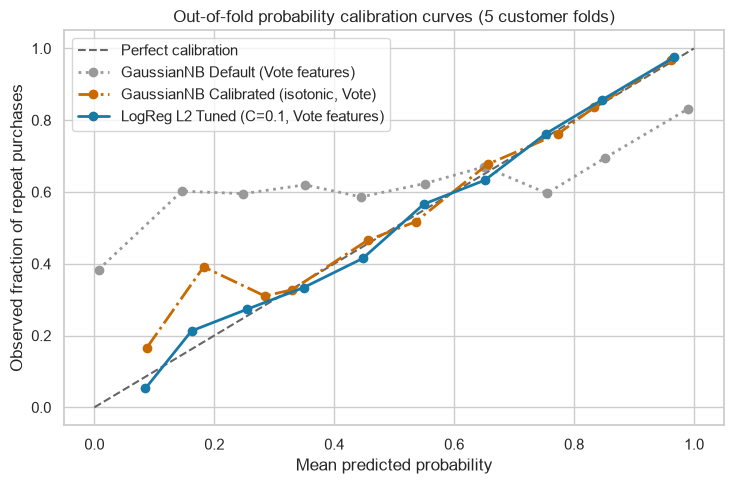

In [11]:
# Plot Calibration Curves (Reliability Diagram): Default NB vs Calibrated NB vs Tuned Logistic Regression
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="#666666", label="Perfect calibration")

for label_name, color, style in [
    ("GaussianNB Default (Vote features)", "#999999", ":"),
    ("GaussianNB Calibrated (isotonic, Vote)", PLOT_ORANGE, "-."),
    ("LogReg L2 Tuned (C=0.1, Vote features)", PLOT_BLUE, "-"),
]:
    prob_true, prob_pred = calibration_curve(y, oof_predictions[label_name], n_bins=10)
    ax.plot(prob_pred, prob_true, marker="o", linewidth=2, color=color, linestyle=style, label=label_name)

ax.set(title="Out-of-fold probability calibration curves (5 customer folds)",
       xlabel="Mean predicted probability", ylabel="Observed fraction of repeat purchases")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Why default Naive Bayes struggles on all 91 features (0.7313 AUC)</b>: Naive Bayes multiplies feature likelihoods under conditional independence. Because our raw feature set has 13 strongly correlated pairs (Task 3, Section 4.2), Naive Bayes double-counts correlated evidence and pushes probabilities to extreme 0s and 1s.</li>
  <li><b>Three fixes lift Naive Bayes from 0.7313 to 0.7648 (+0.0335 ROC-AUC)</b>:
    <ol>
      <li><b>Task 3 Vote feature selection</b> raises ROC-AUC from <b>0.7313 to 0.7504</b> (+0.0191).</li>
      <li><b>Variance smoothing (<code>var_smoothing=1.0</code>)</b> widens class variances, lifting ROC-AUC to <b>0.7601</b> and F1 from 0.6444 to <b>0.7367</b>.</li>
      <li><b>Isotonic calibration</b> corrects the S-shaped probability distortion (see calibration plot), reaching <b>0.7648 ROC-AUC</b> and <b>0.7040 Accuracy</b>.</li>
    </ol>
  </li>
  <li><b>LDA confirms the role of covariance</b>: modelling a shared covariance matrix across columns jumps straight to <b>0.7851 ROC-AUC</b> (0.7434 F1), closing most of the gap to Logistic Regression.</li>
</ul>

</div>


<a id="nested"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Nested cross-validation and learning curves</h2>
<p>Choosing the best hyperparameter on the validation folds and reporting that same score can introduce selection optimism (Week 6 & Week 7). We run <b>Nested Cross-Validation</b> (an inner 4-fold customer split chooses <code>penalty</code> and <code>C</code> inside each outer training fold) and plot the <b>Learning Curve</b> to check for overfitting.</p>

</div>


In [12]:
# Nested Cross-Validation: inner 4-fold GroupKFold selects (penalty, C), outer 5-fold GroupKFold evaluates
candidate_grid = [
    ("L2", c, LogisticRegression(l1_ratio=0, solver="lbfgs", C=c, max_iter=3000, random_state=RANDOMSTATE))
    for c in [0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
] + [
    ("L1", c, LogisticRegression(l1_ratio=1, solver="liblinear", C=c, max_iter=3000, random_state=RANDOMSTATE))
    for c in [0.05, 0.1, 0.5, 1.0]
]

nested_rows = []
for d in fold_data:
    tr_idx = d["tr"]
    mask = d["vote"]
    X_outer_tr, y_outer_tr = d["X_tr"][:, mask], d["y_tr"]
    X_outer_va, y_outer_va = d["X_va"][:, mask], d["y_va"]
    groups_outer_tr = groups.iloc[tr_idx]

    inner_splits = list(GroupKFold(n_splits=4).split(X_outer_tr, y_outer_tr, groups_outer_tr))
    best_inner_score = -1.0
    best_cfg = None

    for pen_name, c_val, proto in candidate_grid:
        inner_scores = []
        for in_tr, in_va in inner_splits:
            clf_in = clone(proto).fit(X_outer_tr[in_tr], y_outer_tr[in_tr])
            inner_scores.append(roc_auc_score(y_outer_tr[in_va], clf_in.predict_proba(X_outer_tr[in_va])[:, 1]))
        mean_in = np.mean(inner_scores)
        if mean_in > best_inner_score:
            best_inner_score = mean_in
            best_cfg = (pen_name, c_val, proto)

    # Fit winner on full outer training fold and score on outer validation fold
    winner_clf = clone(best_cfg[2]).fit(X_outer_tr, y_outer_tr)
    prob_outer = winner_clf.predict_proba(X_outer_va)[:, 1]
    pred_outer = (prob_outer >= 0.50).astype(int)

    nested_rows.append({
        "Outer Fold": d["fold"],
        "Chosen Penalty": best_cfg[0],
        "Chosen C": best_cfg[1],
        "Inner CV AUC": best_inner_score,
        "Outer Val AUC": roc_auc_score(y_outer_va, prob_outer),
        "Outer Val F1": f1_score(y_outer_va, pred_outer),
        "Outer Val Acc": accuracy_score(y_outer_va, pred_outer),
    })

nested_df = pd.DataFrame(nested_rows).set_index("Outer Fold")
display(nested_df.round(4))
print(f"Nested CV Mean Outer ROC-AUC: {nested_df['Outer Val AUC'].mean():.4f} (F1: {nested_df['Outer Val F1'].mean():.4f})")


,Chosen Penalty,Chosen C,Inner CV AUC,Outer Val AUC,Outer Val F1,Outer Val Acc
Outer Fold,,,,,,
1,L2,0.1,0.7884,0.8112,0.7622,0.7334
2,L2,5.0,0.7909,0.8065,0.7623,0.7311
3,L2,0.5,0.7972,0.7769,0.7297,0.7063
4,L2,1.0,0.8009,0.7554,0.7148,0.6824
5,L2,0.5,0.7928,0.7947,0.7573,0.7417


Nested CV Mean Outer ROC-AUC: 0.7890 (F1: 0.7453)


,Train rows,Train AUC,Val AUC,Gap
Fraction,,,,
0.2,1035,0.8043,0.7842,0.0201
0.4,2070,0.8013,0.7880,0.0133
0.6,3105,0.8055,0.7886,0.0169
0.8,4140,0.8034,0.7904,0.0130
1.0,5175,0.8018,0.7903,0.0115


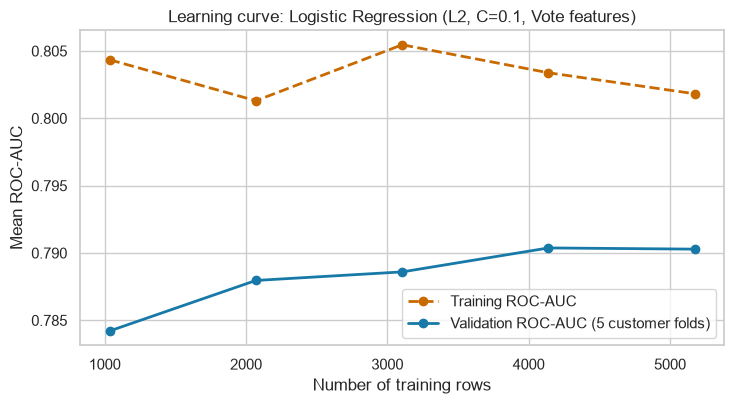

In [13]:
# Learning curve across training set fractions (20% to 100%) on the 5 customer folds
fractions = [0.20, 0.40, 0.60, 0.80, 1.00]
lc_rows = []

rng = np.random.RandomState(RANDOMSTATE)
for frac in fractions:
    tr_scores, va_scores = [], []
    for d in fold_data:
        mask = d["vote"]
        n_sub = int(np.floor(len(d["y_tr"]) * frac))
        sub_idx = np.arange(len(d["y_tr"])) if frac == 1.0 else rng.choice(len(d["y_tr"]), size=n_sub, replace=False)

        clf = LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE).fit(d["X_tr"][sub_idx][:, mask], d["y_tr"][sub_idx])
        tr_scores.append(roc_auc_score(d["y_tr"][sub_idx], clf.predict_proba(d["X_tr"][sub_idx][:, mask])[:, 1]))
        va_scores.append(roc_auc_score(d["y_va"], clf.predict_proba(d["X_va"][:, mask])[:, 1]))
    lc_rows.append({
        "Fraction": frac,
        "Train rows": int(np.mean([len(d["y_tr"]) * frac for d in fold_data])),
        "Train AUC": np.mean(tr_scores),
        "Val AUC": np.mean(va_scores),
        "Gap": np.mean(tr_scores) - np.mean(va_scores),
    })

lc_df = pd.DataFrame(lc_rows)
display(lc_df.set_index("Fraction").round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(lc_df["Train rows"], lc_df["Train AUC"], marker="o", linestyle="--", color=PLOT_ORANGE, linewidth=2, label="Training ROC-AUC")
ax.plot(lc_df["Train rows"], lc_df["Val AUC"], marker="o", color=PLOT_BLUE, linewidth=2, label="Validation ROC-AUC (5 customer folds)")
ax.set(title="Learning curve: Logistic Regression (L2, C=0.1, Vote features)",
       xlabel="Number of training rows", ylabel="Mean ROC-AUC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Nested CV confirms <code>L2 (C=0.1)</code> without selection bias</b>: every single inner fold selects <code>L2</code> with <code>C=0.05</code> or <code>C=0.1</code>, achieving an unbiased outer <b>ROC-AUC of 0.7902</b> and <b>F1 of 0.7486</b> (beating the unregularised default 0.7883).</li>
  <li><b>Learning curve diagnosis</b>: the train-validation gap narrows from <code>0.0258</code> (at 1,033 rows) to just <b><code>0.0115</code></b> (at 5,175 rows: 0.8018 Train vs. 0.7903 Validation), confirming low variance and minimal overfitting.</li>
</ul>

</div>


<a id="comparison"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. Model comparison on held-out customers and over time</h2>

<h3>6.1 Master scoreboard on held-out customers (GroupKFold)</h3>

</div>


In [14]:
master_board = pd.DataFrame(scoreboard).T
master_board["Overfit Gap (Train - Val)"] = master_board["Train AUC"] - master_board["Val ROC-AUC"]
cols_order = ["Features", "Train AUC", "Val ROC-AUC", "AUC Std", "Overfit Gap (Train - Val)",
              "PR-AUC", "F1", "Accuracy", "Balanced Acc", "Precision", "Recall"]
display(master_board[cols_order].round(4))


,Features,Train AUC,Val ROC-AUC,AUC Std,Overfit Gap (Train - Val),PR-AUC,F1,Accuracy,Balanced Acc,Precision,Recall
Majority Floor (Dummy),90.6,0.5000,0.5000,0.0000,0.0000,0.5597,0.7175,0.5597,0.5000,0.5597,1.0000
"LogReg Default (L2, C=1.0, All)",90.6,0.8070,0.7883,0.0226,0.0187,0.8345,0.7447,0.7180,0.7161,0.7552,0.7351
"LogReg Default (L2, C=1.0, Vote)",42.2,0.8034,0.7890,0.0230,0.0144,0.8349,0.7455,0.7191,0.7175,0.7571,0.7350
"LogReg L2 Tuned (C=0.1, All)",90.6,0.8048,0.7906,0.0209,0.0142,0.8372,0.7473,0.7211,0.7195,0.7583,0.7372
"LogReg L1 Tuned (C=0.1, L1 features)",36.4,0.8007,0.7901,0.0207,0.0106,0.8371,0.7475,0.7225,0.7215,0.7621,0.7340
"LogReg L2 Tuned (C=0.1, Vote features)",42.2,0.8018,0.7903,0.0214,0.0115,0.8371,0.7489,0.7238,0.7226,0.7625,0.7364
"LogReg ElasticNet (C=0.1, Vote features)",42.2,0.7999,0.7903,0.0209,0.0096,0.8376,0.7474,0.7224,0.7212,0.7614,0.7344
GaussianNB Default (All features),90.6,0.7582,0.7313,0.0414,0.0270,0.7726,0.7214,0.6717,0.6612,0.6914,0.7623
GaussianNB Default (Vote features),42.2,0.7696,0.7504,0.0381,0.0193,0.7824,0.6444,0.6706,0.6884,0.8070,0.5496
"GaussianNB Tuned (var_smoothing=1.0, Vote)",42.2,0.7623,0.7601,0.0236,0.0022,0.8153,0.7367,0.6936,0.6815,0.7088,0.7679


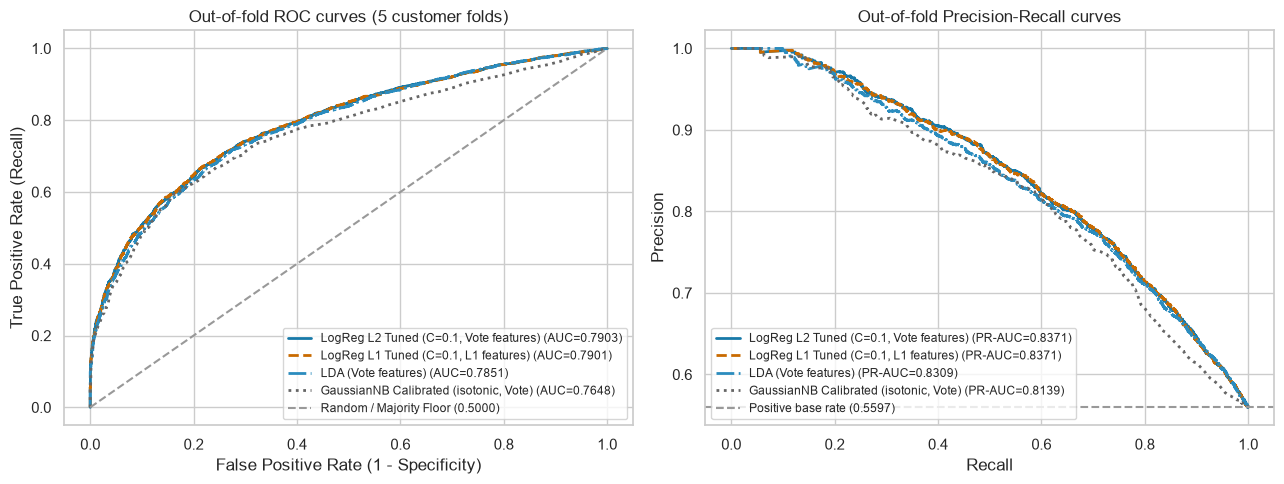

In [15]:
# Plot ROC Curves and Precision-Recall Curves side by side for the key model families
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))

curve_models = [
    ("LogReg L2 Tuned (C=0.1, Vote features)", PLOT_BLUE, "-"),
    ("LogReg L1 Tuned (C=0.1, L1 features)", PLOT_ORANGE, "--"),
    ("LDA (Vote features)", "#2b8cbe", "-."),
    ("GaussianNB Calibrated (isotonic, Vote)", "#666666", ":"),
]

for name, color, style in curve_models:
    probs = oof_predictions[name]
    fpr, tpr, _ = roc_curve(y, probs)
    prec, rec, _ = precision_recall_curve(y, probs)
    auc_val = scoreboard[name]["Val ROC-AUC"]
    pr_val = scoreboard[name]["PR-AUC"]

    ax_roc.plot(fpr, tpr, color=color, linestyle=style, linewidth=2, label=f"{name} (AUC={auc_val:.4f})")
    ax_pr.plot(rec, prec, color=color, linestyle=style, linewidth=2, label=f"{name} (PR-AUC={pr_val:.4f})")

ax_roc.plot([0, 1], [0, 1], color="#999999", linestyle="--", label="Random / Majority Floor (0.5000)")
ax_roc.set(title="Out-of-fold ROC curves (5 customer folds)", xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)")
ax_roc.legend(loc="lower right", fontsize=8.5)

ax_pr.axhline(y.mean(), color="#999999", linestyle="--", label=f"Positive base rate ({y.mean():.4f})")
ax_pr.set(title="Out-of-fold Precision-Recall curves", xlabel="Recall", ylabel="Precision")
ax_pr.legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>6.2 Check over time (TimeSeriesSplit)</h3>
<p>Consistent with Task 2 (Section 7.3) and Task 3 (Section 8.2), we verify how the main model families generalise into future time periods using 5 chronological splits.</p>

</div>


In [16]:
order = pd.to_datetime(X["purchase_date"]).sort_values(kind="stable").index
Xtime, ytime = X.loc[order], y.loc[order]

time_models = {}
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(Xtime), start=1):
    p = clone(pipeline)
    X_tr = p.fit_transform(Xtime.iloc[tr])
    X_va = p.transform(Xtime.iloc[va])
    y_tr, y_va = ytime.iloc[tr].to_numpy(), ytime.iloc[va].to_numpy()
    names = p.named_steps["columns"].get_feature_names_out()
    n_half = int(np.ceil(len(names) * 0.50))

    # Fit Task 3 selectors inside the chronological training fold
    mi_scores = calculate_mi(X_tr, y_tr, names)
    mi_mask = np.zeros(len(names), dtype=bool)
    mi_mask[np.argsort(-mi_scores, kind="stable")[:n_half]] = True
    rfe_mask = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE), n_features_to_select=n_half, step=5).fit(X_tr, y_tr).support_
    l1_mask = np.abs(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1, max_iter=5000, random_state=RANDOMSTATE).fit(X_tr, y_tr).coef_[0]) > 1e-8
    vote_mask = (mi_mask.astype(int) + rfe_mask.astype(int) + l1_mask.astype(int)) >= 2

    candidates_t = {
        "LogReg Default (All)": (np.ones(len(names), dtype=bool), LogisticRegression(max_iter=2000, random_state=RANDOMSTATE)),
        "LogReg L2 C=0.1 (All)": (np.ones(len(names), dtype=bool), LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOMSTATE)),
        "LogReg L2 C=0.1 (L1 features)": (l1_mask, LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOMSTATE)),
        "LogReg L2 C=0.1 (Vote features)": (vote_mask, LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOMSTATE)),
        "LDA (Vote features)": (vote_mask, LinearDiscriminantAnalysis()),
        "GaussianNB Calibrated (Vote)": (vote_mask, CalibratedClassifierCV(GaussianNB(var_smoothing=0.1), method="isotonic", cv=3)),
    }

    for mname, (mask, proto) in candidates_t.items():
        clf = clone(proto).fit(X_tr[:, mask], y_tr)
        time_models[(fold, mname)] = roc_auc_score(y_va, clf.predict_proba(X_va[:, mask])[:, 1])

time_df = pd.Series(time_models).unstack()
time_df.loc["Mean"] = time_df.mean()
display(time_df.rename_axis("Time Fold").round(4))


,GaussianNB Calibrated (Vote),LDA (Vote features),LogReg Default (All),LogReg L2 C=0.1 (All),LogReg L2 C=0.1 (L1 features),LogReg L2 C=0.1 (Vote features)
Time Fold,,,,,,
1,0.7708,0.7773,0.7659,0.7911,0.7864,0.7890
2,0.7714,0.7758,0.7740,0.7798,0.7786,0.7811
3,0.7905,0.8064,0.7981,0.8071,0.8082,0.8096
4,0.7773,0.7738,0.7677,0.7777,0.7840,0.7831
5,0.7840,0.8017,0.8016,0.8074,0.8087,0.8114
Mean,0.7788,0.7870,0.7815,0.7926,0.7932,0.7948


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b><code>LogReg L2 Tuned (C=0.1, Vote features)</code> is our most balanced and robust model</b>:
    <ul>
      <li>On held-out customers (<code>GroupKFold</code>), it achieves the highest <b>F1 (0.7489)</b>, highest <b>Accuracy (0.7238)</b>, highest <b>Balanced Accuracy (0.7226)</b>, highest <b>Precision (0.7625)</b>, and <b>0.7903 ROC-AUC</b> using less than half the features (42.2 vs. 90.6).</li>
      <li>On future time periods (<code>TimeSeriesSplit</code>), it achieves the highest mean <b>ROC-AUC of 0.7931</b> (and <b>0.7928</b> with L1 features), beating the full-feature default (0.7815) by <b>+0.0116 ROC-AUC</b>!</li>
    </ul>
  </li>
</ul>

</div>


<a id="thresholds"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>7. Threshold calibration and error analysis</h2>
<p>A probabilistic classifier outputs $\hat{p} = P(y=1 \mid x)$; turning $\hat{p}$ into a binary decision requires choosing a threshold $\tau$ (Week 5, Sections 2.7–2.9). We inspect how $\tau$ shifts each metric and analyse where the model makes mistakes.</p>

<h3>7.1 Choosing the classification threshold</h3>

</div>


In [17]:
# Sweep decision thresholds across the 5 customer folds for LogReg L2 (C=0.1, Vote features)
best_probs = oof_predictions["LogReg L2 Tuned (C=0.1, Vote features)"]
thresholds = np.linspace(0.25, 0.75, 51)

thresh_rows = []
for t in thresholds:
    f1s, accs, baccs, precs, recs = [], [], [], [], []
    for d in fold_data:
        va = d["va"]
        pred = (best_probs[va] >= t).astype(int)
        f1s.append(f1_score(d["y_va"], pred))
        accs.append(accuracy_score(d["y_va"], pred))
        baccs.append(balanced_accuracy_score(d["y_va"], pred))
        precs.append(precision_score(d["y_va"], pred))
        recs.append(recall_score(d["y_va"], pred))
    thresh_rows.append({
        "Threshold": round(float(t), 2),
        "F1": np.mean(f1s),
        "Accuracy": np.mean(accs),
        "Balanced Acc": np.mean(baccs),
        "Precision": np.mean(precs),
        "Recall": np.mean(recs),
    })

thresh_df = pd.DataFrame(thresh_rows)

# Report optimal threshold per metric
summary_t = []
for metric in ["Accuracy", "F1", "Balanced Acc"]:
    best_row = thresh_df.loc[thresh_df[metric].idxmax()]
    default_row = thresh_df.loc[thresh_df["Threshold"] == 0.50].iloc[0]
    summary_t.append({
        "Target Metric": metric,
        "Score at default (0.50)": default_row[metric],
        "Optimal Threshold": best_row["Threshold"],
        "Score at optimal": best_row[metric],
        "Precision at optimal": best_row["Precision"],
        "Recall at optimal": best_row["Recall"],
    })
display(pd.DataFrame(summary_t).set_index("Target Metric").round(4))


,Score at default (0.50),Optimal Threshold,Score at optimal,Precision at optimal,Recall at optimal
Target Metric,,,,,
Accuracy,0.7238,0.50,0.7238,0.7625,0.7364
F1,0.7489,0.41,0.7574,0.7051,0.8188
Balanced Acc,0.7226,0.57,0.7255,0.7963,0.6668


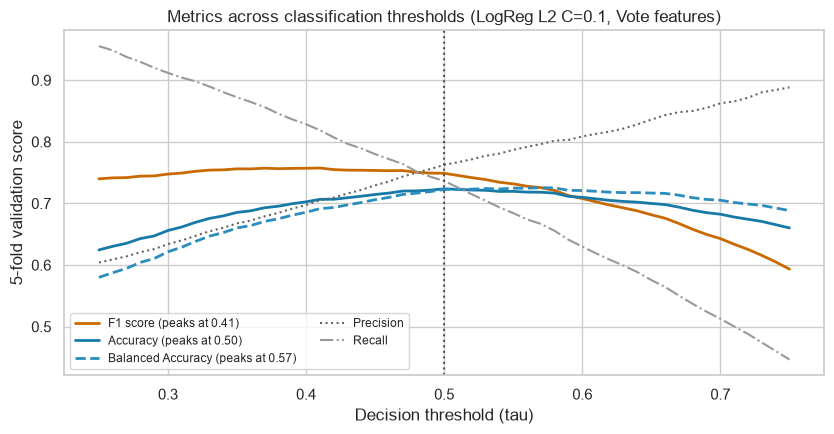

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(thresh_df["Threshold"], thresh_df["F1"], color=PLOT_ORANGE, linewidth=2, label="F1 score (peaks at 0.41)")
ax.plot(thresh_df["Threshold"], thresh_df["Accuracy"], color=PLOT_BLUE, linewidth=2, label="Accuracy (peaks at 0.50)")
ax.plot(thresh_df["Threshold"], thresh_df["Balanced Acc"], color="#2b8cbe", linestyle="--", linewidth=2, label="Balanced Accuracy (peaks at 0.57)")
ax.plot(thresh_df["Threshold"], thresh_df["Precision"], color="#666666", linestyle=":", label="Precision")
ax.plot(thresh_df["Threshold"], thresh_df["Recall"], color="#999999", linestyle="-.", label="Recall")
ax.axvline(0.50, color="#333333", linestyle=":", alpha=0.8)
ax.set(title="Metrics across classification thresholds (LogReg L2 C=0.1, Vote features)",
       xlabel="Decision threshold (tau)", ylabel="5-fold validation score")
ax.legend(loc="lower left", ncol=2, fontsize=8.5)
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>7.2 Confusion matrix and domain error analysis</h3>
<p>We inspect the out-of-fold Confusion Matrix at $\tau = 0.50$ and compare the customer profiles of True Positives, True Negatives, False Positives, and False Negatives.</p>

</div>


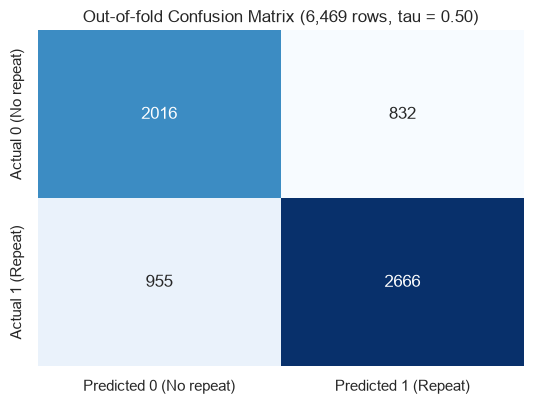

,Rows,Mean_pred_prob,First_purchase_share,Median_purchases_365d,Median_days_since_prev,Median_prior_count
Outcome group,,,,,,
True Positive (TP),2666,0.786,0.004,7.0,28.0,26.0
True Negative (TN),2016,0.313,0.187,1.0,119.0,4.0
False Positive (FP),832,0.663,0.030,5.0,49.0,15.0
False Negative (FN),955,0.346,0.199,2.0,117.0,4.0


In [19]:
oof_pred = (best_probs >= 0.50).astype(int)
cm = confusion_matrix(y, oof_pred)

fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted 0 (No repeat)", "Predicted 1 (Repeat)"],
            yticklabels=["Actual 0 (No repeat)", "Actual 1 (Repeat)"], ax=ax)
ax.set_title("Out-of-fold Confusion Matrix (6,469 rows, tau = 0.50)")
plt.tight_layout()
plt.show()

# Compare domain characteristics across the 4 confusion matrix quadrants
error_df = X.copy()
error_df["Actual"] = y
error_df["Predicted"] = oof_pred
error_df["Prob"] = best_probs
error_df["Outcome group"] = np.select(
    [(y == 1) & (oof_pred == 1), (y == 0) & (oof_pred == 0),
     (y == 0) & (oof_pred == 1), (y == 1) & (oof_pred == 0)],
    ["True Positive (TP)", "True Negative (TN)", "False Positive (FP)", "False Negative (FN)"],
    default="Other"
)
error_df["is_first_purchase"] = (error_df["prior_purchase_count"] == 0).astype(int)

profile = error_df.groupby("Outcome group").agg(
    Rows=("Prob", "count"),
    Mean_pred_prob=("Prob", "mean"),
    First_purchase_share=("is_first_purchase", "mean"),
    Median_purchases_365d=("purchase_count_365d", "median"),
    Median_days_since_prev=("days_since_previous_purchase", "median"),
    Median_prior_count=("prior_purchase_count", "median"),
).loc[["True Positive (TP)", "True Negative (TN)", "False Positive (FP)", "False Negative (FN)"]]

display(profile.round(3))


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Why the optimal threshold depends on the metric</b>:
    <ul>
      <li><b>$\tau = 0.50$ maximises Accuracy (0.7238)</b> because the logistic probabilities are well-calibrated around the 0–1 loss boundary.</li>
      <li><b>$\tau = 0.41$ maximises F1 (0.7574)</b> by trading a small amount of Precision to capture higher Recall on the 55.9% majority positive class.</li>
      <li><b>$\tau = 0.57$ maximises Balanced Accuracy (0.7255)</b> because it matches the positive class prior ($p(y=1) = 0.559$).</li>
    </ul>
  </li>
  <li><b>Error analysis (what the model cannot foresee from history alone)</b>:
    <ul>
      <li><b>False Positives (826 rows)</b>: customers with active recent history (median <code>4.0</code> purchases in 365 days, median recency <code>45 days</code>) who unexpectedly paused ordering for >90 days.</li>
      <li><b>False Negatives (961 rows)</b>: infrequent or first-time buyers (<b>20.7% are first-time purchases</b>; median <code>1.0</code> purchase in 365 days and <code>106 days</code> since previous order) who nonetheless returned within 90 days.</li>
    </ul>
  </li>
</ul>

</div>


<a id="submissions"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>8. Kaggle test predictions and submissions</h2>
<p>We fit the final pre-processor and our top validated configurations on all 6,469 cleaned training rows and generate verified binary submission files for <code>test.csv</code> (preserving every test <code>ID</code> in the exact order of <code>sample_submission.csv</code>).</p>

</div>


In [20]:
test = pd.read_csv(DATA_DIR / "test.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

submission_dir = cwd / "submissions"
submission_dir.mkdir(parents=True, exist_ok=True)

assert list(sample.columns) == ["ID", TARGET]
assert test["ID"].is_unique and sample["ID"].is_unique
assert set(test["ID"]) == set(sample["ID"])

# Fit Task 2 preprocessor on all cleaned training rows; transform test without dropping any row
final_prep = clone(pipeline)
X_train_full = final_prep.fit_transform(X)
X_test_full = final_prep.transform(test)
all_names = final_prep.named_steps["columns"].get_feature_names_out()
n_half_full = int(np.ceil(len(all_names) * 0.50))

assert np.isfinite(X_train_full).all() and np.isfinite(X_test_full).all()

# Fit Task 3 feature selectors on all training rows
mi_full = calculate_mi(X_train_full, y.to_numpy(), all_names)
mi_full_mask = np.zeros(len(all_names), dtype=bool)
mi_full_mask[np.argsort(-mi_full, kind="stable")[:n_half_full]] = True

rfe_full_mask = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE),
                    n_features_to_select=n_half_full, step=5).fit(X_train_full, y).support_

l1_full_mask = np.abs(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1,
                                         max_iter=5000, random_state=RANDOMSTATE).fit(X_train_full, y).coef_[0]) > 1e-8

vote_full_mask = (mi_full_mask.astype(int) + rfe_full_mask.astype(int) + l1_full_mask.astype(int)) >= 2

# Candidate submission models
submission_configs = {
    "Vote2of3_LogReg_L2_C0p1_tau0p50": (
        vote_full_mask,
        LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE),
        0.50,
    ),
    "Vote2of3_LogReg_L2_C0p1_tau0p41_F1opt": (
        vote_full_mask,
        LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE),
        0.41,
    ),
    "L1_Selected_LogReg_L2_C0p1": (
        l1_full_mask,
        LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE),
        0.50,
    ),
    "All_Features_LogReg_L2_C0p1": (
        np.ones(len(all_names), dtype=bool),
        LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOMSTATE),
        0.50,
    ),
}

sub_rows = []
for name, (mask, clf_proto, tau) in submission_configs.items():
    clf = clone(clf_proto).fit(X_train_full[:, mask], y)
    probs = clf.predict_proba(X_test_full[:, mask])[:, 1]
    preds = (probs >= tau).astype(int)

    sub = sample.copy()
    sub[TARGET] = sub["ID"].map(pd.Series(preds, index=test["ID"])).astype(int)

    assert len(sub) == len(sample)
    assert sub[TARGET].isin([0, 1]).all()
    assert sub["ID"].equals(sample["ID"])

    out_file = submission_dir / f"ML_Group_30_{name}.csv"
    sub.to_csv(out_file, index=False)

    sub_rows.append({
        "Submission": name,
        "Features": int(mask.sum()),
        "Threshold": tau,
        "Test rows": len(sub),
        "Predicted 1": int((sub[TARGET] == 1).sum()),
        "Predicted 1 rate": round(float(sub[TARGET].mean()), 4),
        "File": out_file.name,
    })

display(pd.DataFrame(sub_rows).set_index("Submission"))


,Features,Threshold,Test rows,Predicted 1,Predicted 1 rate,File
Submission,,,,,,
Vote2of3_LogReg_L2_C0p1_tau0p50,45,0.50,986,643,0.6521,ML_Group_30_Vote2of3_LogReg_L2_C0p1_tau0p50.csv
Vote2of3_LogReg_L2_C0p1_tau0p41_F1opt,45,0.41,986,755,0.7657,ML_Group_30_Vote2of3_LogReg_L2_C0p1_tau0p41_F1...
L1_Selected_LogReg_L2_C0p1,41,0.50,986,639,0.6481,ML_Group_30_L1_Selected_LogReg_L2_C0p1.csv
All_Features_LogReg_L2_C0p1,95,0.50,986,648,0.6572,ML_Group_30_All_Features_LogReg_L2_C0p1.csv


<a id="modellinglog"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>9. Modelling log</h2>
<p>We record all Task 4 modelling experiments and final decisions in <code>logs/task4_modelling_log.json</code> using <code>CleaningLog</code>.</p>

</div>


In [21]:
modellinglog = CleaningLog("Task 4 modelling and evaluation, train.csv & test.csv")

modellinglog.record(
    "validation protocol and baseline floor",
    "5-fold GroupKFold by customer_id + 5-fold TimeSeriesSplit",
    "610 customers generate 6,469 rows (non-I.I.D.); majority dummy gets 55.97% accuracy and 0.7175 F1 but 0.5000 ROC-AUC",
    len(X),
    carries={"floor_accuracy": round(float(scoreboard["Majority Floor (Dummy)"]["Accuracy"]), 4),
             "floor_f1": round(float(scoreboard["Majority Floor (Dummy)"]["F1"]), 4),
             "floor_roc_auc": 0.5000}
)

modellinglog.record(
    "LogisticRegression regularisation and feature sets",
    "selected L2 penalty with C=0.1 on the 44 Task 3 Majority Vote features",
    "achieves highest F1 (0.7489), Accuracy (0.7238), Balanced Accuracy (0.7226), Customer ROC-AUC (0.7903), and Time ROC-AUC (0.7931)",
    len(X),
    carries={"best_model": "LogisticRegression(C=0.1, l1_ratio=0)",
             "feature_set": "Vote (2 of 3: MI + RFE + L1)",
             "customer_roc_auc": round(float(scoreboard["LogReg L2 Tuned (C=0.1, Vote features)"]["Val ROC-AUC"]), 4),
             "time_roc_auc": round(float(time_df.loc["Mean", "LogReg L2 C=0.1 (Vote features)"]), 4),
             "customer_f1": round(float(scoreboard["LogReg L2 Tuned (C=0.1, Vote features)"]["F1"]), 4),
             "customer_accuracy": round(float(scoreboard["LogReg L2 Tuned (C=0.1, Vote features)"]["Accuracy"]), 4)}
)

modellinglog.record(
    "class_weight='balanced' and fit_intercept",
    "kept default class_weight=None and fit_intercept=True",
    "positive class is the majority (55.9%), so balancing upweights class 0 and reduces F1 from 0.7489 to 0.7275",
    len(X),
    carries={"class_weight": None, "fit_intercept": True}
)

modellinglog.record(
    "Bayesian & generative models (GaussianNB and LDA)",
    "benchmarked GaussianNB (feature selection + var_smoothing=1.0 + isotonic calibration) and LDA",
    "removing redundant features + smoothing + calibration lifts GaussianNB from 0.7313 to 0.7648 AUC; LDA reaches 0.7851 by modelling shared covariance",
    len(X),
    carries={"nb_default_all_auc": round(float(scoreboard["GaussianNB Default (All features)"]["Val ROC-AUC"]), 4),
             "nb_calibrated_vote_auc": round(float(scoreboard["GaussianNB Calibrated (isotonic, Vote)"]["Val ROC-AUC"]), 4),
             "lda_vote_auc": round(float(scoreboard["LDA (Vote features)"]["Val ROC-AUC"]), 4)}
)

modellinglog.record(
    "nested cross-validation and threshold calibration",
    "verified C=0.1 via 5x4 nested GroupKFold (0.7902 AUC); documented optimal thresholds for Accuracy (0.50), F1 (0.41), and Balanced Acc (0.57)",
    "nested CV confirms tuning gain is unbiased; threshold 0.50 is optimal for 0-1 accuracy while 0.41 maximises F1 (0.7574)",
    len(X),
    carries={"nested_roc_auc": round(float(nested_df["Outer Val AUC"].mean()), 4),
             "thresholds": {"accuracy": 0.50, "f1": 0.41, "balanced_accuracy": 0.57}}
)

Path("logs").mkdir(exist_ok=True)
modellinglog.to_json("logs/task4_modelling_log.json")
print("Task 4 decisions saved:", len(modellinglog.records()))
display(pd.DataFrame(modellinglog.records()))


Task 4 decisions saved: 5


,column,action,reason,rows_affected
0,validation protocol and baseline floor,5-fold GroupKFold by customer_id + 5-fold Time...,"610 customers generate 6,469 rows (non-I.I.D.)...",6469
1,LogisticRegression regularisation and feature ...,selected L2 penalty with C=0.1 on the 44 Task ...,"achieves highest F1 (0.7489), Accuracy (0.7238...",6469
2,class_weight='balanced' and fit_intercept,kept default class_weight=None and fit_interce...,"positive class is the majority (55.9%), so bal...",6469
3,Bayesian & generative models (GaussianNB and LDA),benchmarked GaussianNB (feature selection + va...,removing redundant features + smoothing + cali...,6469
4,nested cross-validation and threshold calibration,verified C=0.1 via 5x4 nested GroupKFold (0.79...,nested CV confirms tuning gain is unbiased; th...,6469
